# Hotel Booking Analytics

## Project Overview

This project analyzes hotel booking data to understand booking patterns,
guest behavior, cancellations, seasonality, and hotel performance.

The analysis follows an end-to-end data analytics workflow using Python,
SQL, and Power BI.

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Dataset

In [ ]:
df = pd.read_csv("hotel_bookings.csv")

## 3. Initial Data Inspection

In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.shape

(119390, 32)

In [ ]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
df .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
df.describe(include= "object")

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


## 4. Data Quality Assessment

In [ ]:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [ ]:
df.duplicated().sum()

np.int64(31994)

In [ ]:
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


### 4.1 Missing Values Analysis

---



In [ ]:
(df.isnull().sum() / len(df)* 100). sort_values(ascending= False)

,0
company,94.306893
agent,13.686238
country,0.408744
children,0.003350
arrival_date_month,0.000000
arrival_date_week_number,0.000000
hotel,0.000000
is_canceled,0.000000
stays_in_weekend_nights,0.000000
arrival_date_day_of_month,0.000000


In [ ]:
df[["children", "country", "agent", "company"]].head(20)

,children,country,agent,company
0,0.0,PRT,NaN,NaN
1,0.0,PRT,NaN,NaN
2,0.0,GBR,NaN,NaN
3,0.0,GBR,304.0,NaN
4,0.0,GBR,240.0,NaN
5,0.0,GBR,240.0,NaN
6,0.0,PRT,NaN,NaN
7,0.0,PRT,303.0,NaN
8,0.0,PRT,240.0,NaN
9,0.0,PRT,15.0,NaN


In [ ]:
df["agent"].value_counts().head(10)

,count
agent,
9.0,31961
240.0,13922
1.0,7191
14.0,3640
7.0,3539
6.0,3290
250.0,2870
241.0,1721
28.0,1666


In [ ]:
df["company"].value_counts().head(10)

,count
company,
40.0,927
223.0,784
67.0,267
45.0,250
153.0,215
174.0,149
219.0,141
281.0,138
154.0,133


### 4.2 Handling Missing Values

In [ ]:
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)

In [ ]:
df["children"] = df["children"].astype(int)
df["agent"] = df["agent"].astype(int)
df["company"] = df["company"].astype(int)

In [ ]:
df[["children", "country", "agent", "company"]].isnull().sum()

,0
children,0
country,0
agent,0
company,0


In [ ]:
df[["children", "agent", "company"]].dtypes

,0
children,int64
agent,int64
company,int64


### 4.3 Duplicate Analysis

In [ ]:
duplicate_rows = df[df.duplicated(keep = False)]
duplicate_rows.shape

(40165, 32)

In [ ]:
duplicate_rows.sort_values(by = ["hotel", "arrival_date_year", "arrival_date_month", "arrival_date_day_of_month"]).head(20)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40562,City Hotel,0,117,2015,August,31,1,2,1,1,...,No Deposit,17,0,0,Transient-Party,72.5,0,0,Check-Out,2015-08-04
40563,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40564,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40566,City Hotel,0,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Check-Out,2015-08-04
40567,City Hotel,0,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Check-Out,2015-08-04
40568,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40569,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40570,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40573,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40574,City Hotel,1,2,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-30


In [ ]:
duplicate_rows.nunique()

,0
hotel,2
is_canceled,2
lead_time,455
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,9
stays_in_week_nights,18
adults,5


#### 4.3.1 Investigate exact duplicate groups

In [ ]:
duplicate_counts = df.groupby(list(df.columns)).size().sort_values(ascending=False)

duplicate_counts.head(20)

hotel       is_canceled  lead_time  arrival_date_year  arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  stays_in_weekend_nights  stays_in_week_nights  adults  children  babies  meal  country  market_segment  distribution_channel  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled  reserved_room_type  assigned_room_type  booking_changes  deposit_type  agent  company  days_in_waiting_list  customer_type    adr    required_car_parking_spaces  total_of_special_requests  reservation_status  reservation_status_date
City Hotel  1            277        2016               November            46                        7                          1                        2                     2       0         0       BB    PRT      Groups          TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    0      0        0                     Transient        100.0  0                            0                          Canceled            2016-04-04                 180
                         68         2016               February            8                         17                         0                        2                     2       0         0       BB    PRT      Groups          TA/TO                 0                  1                       0                               A                   A                   0                Non Refund    37     0        0                     Transient        75.0   0                            0                          Canceled            2016-01-06                 150
                         188        2016               June                25                        15                         0                        2                     1       0         0       BB    PRT      Offline TA/TO   TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    119    0        39                    Transient        130.0  0                            0                          Canceled            2016-01-18                 109
                         158        2016               May                 22                        24                         0                        2                     1       0         0       BB    PRT      Groups          TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    37     0        31                    Transient        130.0  0                            0                          Canceled            2016-01-18                 101
                         34         2015               December            50                        8                          0                        2                     1       0         0       BB    PRT      Offline TA/TO   TA/TO                 0                  1                       0                               A                   A                   0                Non Refund    19     0        0                     Transient        90.0   0                            0                          Canceled            2015-11-17                 100
                         38         2017               January             2                         14                         0                        1                     1       0         0       BB    PRT      Corporate       Corporate             0                  0                       0                               A                   A                   0                Non Refund    0      67       0                     Transient        75.0   0                            0                          Canceled            2016-12-07                  99
                        

In [ ]:
duplicate_counts.describe()

,0
count,87396.000000
mean,1.366081
std,2.771488
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,180.000000


In [ ]:
duplicate_counts[duplicate_counts > 1].head(20)

hotel       is_canceled  lead_time  arrival_date_year  arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  stays_in_weekend_nights  stays_in_week_nights  adults  children  babies  meal  country  market_segment  distribution_channel  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled  reserved_room_type  assigned_room_type  booking_changes  deposit_type  agent  company  days_in_waiting_list  customer_type    adr    required_car_parking_spaces  total_of_special_requests  reservation_status  reservation_status_date
City Hotel  1            277        2016               November            46                        7                          1                        2                     2       0         0       BB    PRT      Groups          TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    0      0        0                     Transient        100.0  0                            0                          Canceled            2016-04-04                 180
                         68         2016               February            8                         17                         0                        2                     2       0         0       BB    PRT      Groups          TA/TO                 0                  1                       0                               A                   A                   0                Non Refund    37     0        0                     Transient        75.0   0                            0                          Canceled            2016-01-06                 150
                         188        2016               June                25                        15                         0                        2                     1       0         0       BB    PRT      Offline TA/TO   TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    119    0        39                    Transient        130.0  0                            0                          Canceled            2016-01-18                 109
                         158        2016               May                 22                        24                         0                        2                     1       0         0       BB    PRT      Groups          TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    37     0        31                    Transient        130.0  0                            0                          Canceled            2016-01-18                 101
                         34         2015               December            50                        8                          0                        2                     1       0         0       BB    PRT      Offline TA/TO   TA/TO                 0                  1                       0                               A                   A                   0                Non Refund    19     0        0                     Transient        90.0   0                            0                          Canceled            2015-11-17                 100
                         38         2017               January             2                         14                         0                        1                     1       0         0       BB    PRT      Corporate       Corporate             0                  0                       0                               A                   A                   0                Non Refund    0      67       0                     Transient        75.0   0                            0                          Canceled            2016-12-07                  99
                        

**Duplicate Decision:**

The dataset contains 31,994 exact duplicate rows. However, the dataset
does not contain a unique booking ID or guest identifier. Multiple
bookings may therefore legitimately have identical characteristics,
particularly for group bookings, travel-agent bookings, and bookings
with standardized rates.

Removing these records could understate actual booking volume and affect
cancellation and demand analysis. Therefore, exact duplicate rows were
retained for this analysis.

### 4.4 Data Type & Date Validation

In [ ]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
df[["arrival_date_year", "arrival_date_month", "arrival_date_day_of_month", "reservation_status_date"]].head(10)

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,reservation_status_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-02
3,2015,July,1,2015-07-02
4,2015,July,1,2015-07-03
5,2015,July,1,2015-07-03
6,2015,July,1,2015-07-03
7,2015,July,1,2015-07-03
8,2015,July,1,2015-05-06
9,2015,July,1,2015-04-22


#### 4.4.1 Date Conversion

In [ ]:
df["arrival_date"] = pd.to_datetime(df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d")

In [ ]:
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

In [ ]:
df[["arrival_date", "reservation_status_date"]].head(10)

,arrival_date,reservation_status_date
0,2015-07-01,2015-07-01
1,2015-07-01,2015-07-01
2,2015-07-01,2015-07-02
3,2015-07-01,2015-07-02
4,2015-07-01,2015-07-03
5,2015-07-01,2015-07-03
6,2015-07-01,2015-07-03
7,2015-07-01,2015-07-03
8,2015-07-01,2015-05-06
9,2015-07-01,2015-04-22


In [ ]:
df[["arrival_date", "reservation_status_date"]].dtypes

,0
arrival_date,datetime64[ns]
reservation_status_date,datetime64[ns]


#### 4.4.2 Date Validation

In [ ]:
df[["arrival_date", "reservation_status_date"]].agg(["min", "max"])

,arrival_date,reservation_status_date
min,2015-07-01,2014-10-17
max,2017-08-31,2017-09-14


In [ ]:
df[["arrival_date", "reservation_status_date"]].isnull().sum()

,0
arrival_date,0
reservation_status_date,0


In [ ]:
df["reservation_status"].value_counts()

,count
reservation_status,
Check-Out,75166
Canceled,43017
No-Show,1207


### 4.5 Data Consistency Validation

In [ ]:
df[["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "adr"]].describe()

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,104.011416,0.927599,2.500302,1.856403,0.103886,0.007949,101.831122
std,106.863097,0.998613,1.908286,0.579261,0.398555,0.097436,50.535790
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,0.000000,69.290000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,0.000000,94.575000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,0.000000,126.000000
max,737.000000,19.000000,50.000000,55.000000,10.000000,10.000000,5400.000000


In [ ]:
df[(df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)].shape

(180, 33)

In [ ]:
df[df["adr"] < 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,273,0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15,2017-03-05


#### 4.5.1 Investigating Invalid Guest Counts

In [ ]:
zero_guests = df[(df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)]

zero_guests["reservation_status"].value_counts()

,count
reservation_status,
Check-Out,155
Canceled,24
No-Show,1


In [ ]:
zero_guests["hotel"].value_counts()

,count
hotel,
City Hotel,167
Resort Hotel,13


In [ ]:
zero_guests[[ "adults", "children", "babies", "stays_in_weekend_nights", "stays_in_week_nights", "adr", "reservation_status"]].head(20)

,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,adr,reservation_status
2224,0,0,0,0,3,0.0,Check-Out
2409,0,0,0,0,0,0.0,Check-Out
3181,0,0,0,1,2,0.0,Check-Out
3684,0,0,0,1,4,0.0,Check-Out
3708,0,0,0,2,4,0.0,Check-Out
4127,0,0,0,0,0,0.0,Canceled
9376,0,0,0,0,0,0.0,Canceled
31765,0,0,0,2,8,28.0,Check-Out
32029,0,0,0,0,1,0.0,Check-Out
32827,0,0,0,3,9,0.0,Check-Out


**Cleaning Decision:**

The dataset contains 180 bookings with zero adults, children
and babies. Of these, 155 have Check-Out status, 24 were
canceled and 1 was a no-show.

Because the correct guest counts cannot be determined,
these records were excluded from the cleaned analytical
dataset. The original dataset remains unchanged.

This decision removes approximately 0.15% of the records.

In [ ]:
df = df[(df["adults"] + df["children"] + df["babies"]) > 0].copy()

df.shape

(119210, 33)

#### 4.5.2 Investigating ADR

In [ ]:
df["adr"].describe()

,adr
count,119210.000000
mean,101.969092
std,50.434007
min,-6.380000
25%,69.500000
50%,94.950000
75%,126.000000
max,5400.000000


In [ ]:
df[df["adr"] > 1000][["hotel", "adr", "adults", "children", "stays_in_weekend_nights", "stays_in_week_nights", "reservation_status"]]

,hotel,adr,adults,children,stays_in_weekend_nights,stays_in_week_nights,reservation_status
48515,City Hotel,5400.0,2,0,0,1,Canceled


**ADR Cleaning Decision:**

One booking has a negative ADR of -6.38 and is excluded
from the cleaned dataset.

One canceled booking has an unusually high ADR of 5,400.
The booking is retained for cancellation analysis, but
its ADR is marked as missing to exclude it from standard
pricing calculations.

Both decisions are documented because the original
values cannot be independently verified.

In [ ]:
# Remove the booking with negative ADR
df = df[df["adr"] >= 0].copy()

# Exclude the extreme ADR from pricing calculations
df.loc[df["adr"] > 1000, "adr"] = np.nan

# Verify the results
print("Dataset shape:", df.shape)
print("Negative ADR:", (df["adr"] < 0).sum())
print("Missing ADR:", df["adr"].isnull().sum())
print("Maximum valid ADR:", df["adr"].max())

Dataset shape: (119209, 33)
Negative ADR: 0
Missing ADR: 1
Maximum valid ADR: 510.0


#### 4.5.3 Investigating Unusual Guest Counts and Stay Lengths

In [ ]:
df[(df["adults"] > 10) | (df["children"] > 5) | (df["babies"] > 5)][["hotel", "adults", "children", "babies", "adr", "reservation_status"]]

,hotel,adults,children,babies,adr,reservation_status
328,Resort Hotel,2,10,0,133.16,No-Show
1539,Resort Hotel,40,0,0,0.00,Canceled
1587,Resort Hotel,26,0,0,0.00,Canceled
1643,Resort Hotel,50,0,0,0.00,Canceled
1752,Resort Hotel,26,0,0,0.00,Canceled
1884,Resort Hotel,26,0,0,0.00,Canceled
1917,Resort Hotel,27,0,0,0.00,Canceled
1962,Resort Hotel,27,0,0,0.00,Canceled
2003,Resort Hotel,26,0,0,0.00,Canceled
2164,Resort Hotel,26,0,0,0.00,Canceled


In [ ]:
df[(df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) > 30][[ "hotel", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "adr", "reservation_status"]]

,hotel,stays_in_weekend_nights,stays_in_week_nights,adults,adr,reservation_status
1655,Resort Hotel,13,33,2,0.00,Check-Out
3820,Resort Hotel,12,30,2,22.11,Canceled
3850,Resort Hotel,12,30,2,31.45,Check-Out
5344,Resort Hotel,9,24,2,77.00,Canceled
9839,Resort Hotel,16,40,2,25.50,Canceled
14037,Resort Hotel,18,42,1,110.50,Check-Out
14038,Resort Hotel,19,50,1,110.00,Check-Out
20835,Resort Hotel,10,25,1,36.93,Check-Out
31404,Resort Hotel,10,25,1,41.98,Check-Out
32589,Resort Hotel,13,32,1,42.11,Check-Out


In [ ]:
df[(df["stays_in_weekend_nights"] == 0) & (df["stays_in_week_nights"] == 0)]["reservation_status"].value_counts()

,count
reservation_status,
Check-Out,622
No-Show,13
Canceled,10


#### 4.5.4 Investigating Zero-Night Bookings

In [ ]:

zero_nights = df[(df["stays_in_weekend_nights"] == 0) & (df["stays_in_week_nights"] == 0)]

zero_nights.groupby("reservation_status")["adr"].describe()

,count,mean,std,min,25%,50%,75%,max
reservation_status,,,,,,,,
Canceled,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Check-Out,622.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
No-Show,13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
pd.crosstab(zero_nights["hotel"], zero_nights["reservation_status"])

reservation_status,Canceled,Check-Out,No-Show
hotel,,,
City Hotel,6,251,7
Resort Hotel,4,371,6



**Zero-Night Booking Decision:**

The dataset contains 645 zero-night bookings, all with
an ADR of zero. Of these, 622 have Check-Out status,
10 were canceled and 13 were no-shows.

These bookings were retained because their validity
cannot be determined from the available data.

A zero-night flag was created to distinguish them
from overnight bookings. They will be excluded from
overnight-stay and occupied-room pricing metrics.

In [ ]:
# Create a flag for zero-night bookings
df["is_zero_night"] = ((df["stays_in_weekend_nights"] == 0) & (df["stays_in_week_nights"] == 0)).astype(int)

# Verify the results
print("Zero-night bookings:", df["is_zero_night"].sum())
print("Dataset shape:", df.shape)

Zero-night bookings: 645
Dataset shape: (119209, 34)


# 5. Data Preparation for Analysis
### 5.1 Total Nights

In [ ]:
df["total_nights"] = (df["stays_in_weekend_nights"] + df["stays_in_week_nights"])

df["total_nights"].describe()

,total_nights
count,119209.000000
mean,3.426193
std,2.540632
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,69.000000


### 5.2 Total Guests

In [ ]:
df["total_guests"] = (df["adults"] + df["children"] + df["babies"])

df["total_guests"].describe()

,total_guests
count,119209.000000
mean,1.971210
std,0.718879
min,1.000000
25%,2.000000
50%,2.000000
75%,2.000000
max,55.000000


### 5.3 Arrival Month Number

In [ ]:
# Extract the month number from the arrival date
df["arrival_month_number"] = df["arrival_date"].dt.month

# Verify the results
df[["arrival_date", "arrival_date_month", "arrival_month_number"]].head(10)

,arrival_date,arrival_date_month,arrival_month_number
0,2015-07-01,July,7
1,2015-07-01,July,7
2,2015-07-01,July,7
3,2015-07-01,July,7
4,2015-07-01,July,7
5,2015-07-01,July,7
6,2015-07-01,July,7
7,2015-07-01,July,7
8,2015-07-01,July,7
9,2015-07-01,July,7


### 5.4 Estimated Booking Revenue

In [ ]:
# Calculate estimated booking revenue
df["estimated_revenue"] = df["adr"] * df["total_nights"]

# Review the results
df[["hotel", "adr", "total_nights", "estimated_revenue", "reservation_status"]].head(10)

,hotel,adr,total_nights,estimated_revenue,reservation_status
0,Resort Hotel,0.0,0,0.0,Check-Out
1,Resort Hotel,0.0,0,0.0,Check-Out
2,Resort Hotel,75.0,1,75.0,Check-Out
3,Resort Hotel,75.0,1,75.0,Check-Out
4,Resort Hotel,98.0,2,196.0,Check-Out
5,Resort Hotel,98.0,2,196.0,Check-Out
6,Resort Hotel,107.0,2,214.0,Check-Out
7,Resort Hotel,103.0,2,206.0,Check-Out
8,Resort Hotel,82.0,3,246.0,Canceled
9,Resort Hotel,105.5,3,316.5,Canceled


### 5.5 Estimated Completed-Stay Revenue

In [ ]:
# Calculate estimated revenue for completed stays only
df["completed_stay_revenue"] = df["estimated_revenue"].where(df["reservation_status"] == "Check-Out", 0)

# Review the results
df[["hotel", "reservation_status", "total_nights", "estimated_revenue", "completed_stay_revenue"]].head(10)

,hotel,reservation_status,total_nights,estimated_revenue,completed_stay_revenue
0,Resort Hotel,Check-Out,0,0.0,0.0
1,Resort Hotel,Check-Out,0,0.0,0.0
2,Resort Hotel,Check-Out,1,75.0,75.0
3,Resort Hotel,Check-Out,1,75.0,75.0
4,Resort Hotel,Check-Out,2,196.0,196.0
5,Resort Hotel,Check-Out,2,196.0,196.0
6,Resort Hotel,Check-Out,2,214.0,214.0
7,Resort Hotel,Check-Out,2,206.0,206.0
8,Resort Hotel,Canceled,3,246.0,0.0
9,Resort Hotel,Canceled,3,316.5,0.0


### 5.6 Booking Lead Time Categories

In [ ]:
# Categorize bookings based on lead time
df["lead_time_category"] = pd.cut(df["lead_time"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=[ "0-7 days", "8-30 days", "31-90 days", "91-180 days", "181+ days"])

# Check the distribution
df["lead_time_category"].value_counts(sort=False)

,count
lead_time_category,
0-7 days,19635
8-30 days,18945
31-90 days,29529
91-180 days,26420
181+ days,24680


### 5.7 Room Type Changes

In [ ]:

# Identify bookings with a different assigned room type

df["room_type_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)

# Check the distribution
df["room_type_changed"].value_counts()

,count
room_type_changed,
0,104414
1,14795


###Analysis
Of the 119,209 bookings, 12.41% had a different assigned room type from the originally reserved room type, while 87.59% remained unchanged.

### 5.8 Final Data Preparation Checks

In [ ]:
# Check the final dataset dimensions
print("Dataset shape:", df.shape)

# Check missing values
print()
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check the new columns
print()
print("New analysis columns:")
print(df[["is_zero_night", "total_nights", "total_guests", "arrival_month_number", "estimated_revenue", "completed_stay_revenue", "lead_time_category", "room_type_changed"]].dtypes)

Dataset shape: (119209, 41)

Missing values:
adr                  1
estimated_revenue    1
dtype: int64

New analysis columns:
is_zero_night                int64
total_nights                 int64
total_guests                 int64
arrival_month_number         int32
estimated_revenue          float64
completed_stay_revenue     float64
lead_time_category        category
room_type_changed            int64
dtype: object


### Final Data Validation
- The prepared dataset contains 119,209 rows and 41 columns.
- All eight new analysis columns were successfully created.
- Two columns contain one missing value each: `adr` and `estimated_revenue`.
- These missing values are intentional. The unusually high ADR of 5,400 was marked as missing because it could not be independently verified.
- The corresponding estimated revenue is also missing because it is calculated using ADR.
- Both missing values are retained to avoid introducing inaccurate pricing information.

**Conclusion:** The dataset now is prepared for Exploratory Data Analysis (EDA).


## 6. Exploratory Data Analysis (EDA)

### 6.1 Hotel Booking Distribution

**Question:** How are bookings distributed between City Hotel and Resort Hotel?

In [ ]:
# Count bookings by hotel type
df["hotel"].value_counts()

,count
hotel,
City Hotel,79163
Resort Hotel,40046


In [ ]:
# Calculate the percentage of bookings by hotel type
df["hotel"].value_counts(normalize=True) * 100

,proportion
hotel,
City Hotel,66.406899
Resort Hotel,33.593101


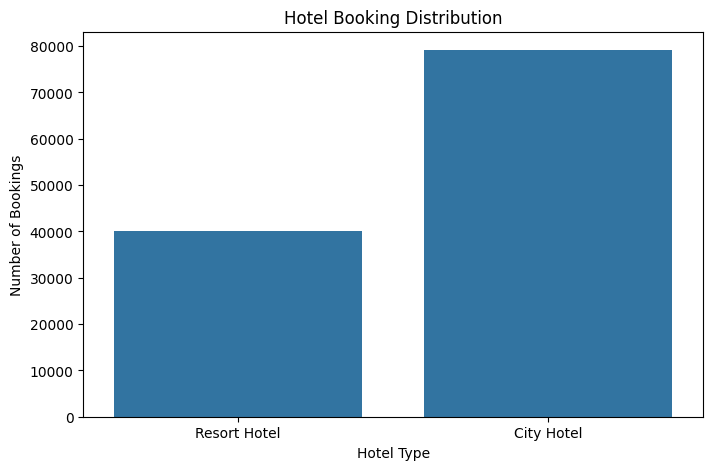

In [ ]:
# Visualize hotel booking distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="hotel")

plt.title("Hotel Booking Distribution")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.show()

**Analysis:**

- City Hotel received 79,163 bookings (66.41%).
- Resort Hotel received 40,046 bookings (33.59%).
- City Hotel accounted for approximately two-thirds of all bookings.

**Insight:**

City Hotel has a substantially higher booking volume than Resort Hotel. Further analysis is needed to determine whether this difference is also reflected in cancellation rates, seasonal demand and estimated revenue.

### 6.2 Booking Cancellation Analysis

**Question:** What percentage of bookings were canceled, and how do cancellation rates differ between City Hotel and Resort Hotel?

In [ ]:
# Count canceled and non-canceled bookings
df["is_canceled"].value_counts()

,count
is_canceled,
0,75010
1,44199


In [ ]:
# Calculate the overall cancellation percentage
df["is_canceled"].value_counts(normalize=True) * 100

,proportion
is_canceled,
0,62.923101
1,37.076899


In [ ]:
# Calculate cancellation rates by hotel type
pd.crosstab(df["hotel"], df["is_canceled"], normalize="index") * 100

is_canceled,0,1
hotel,,
City Hotel,58.214065,41.785935
Resort Hotel,72.231933,27.768067


**Analysis:**

- Out of 119,209 bookings, 44,199 (37.08%) were canceled.
- The remaining 75,010 bookings (62.92%) were not canceled.
- City Hotel recorded a cancellation rate of 41.79%.
- Resort Hotel recorded a cancellation rate of 27.77%.
- City Hotel's cancellation rate was approximately 14 percentage points higher than Resort Hotel's.

**Insight:**

City Hotel experiences a higher proportion of cancellations than Resort Hotel. Further investigation of booking lead times, deposit types and distribution channels may help identify factors associated with cancellations.

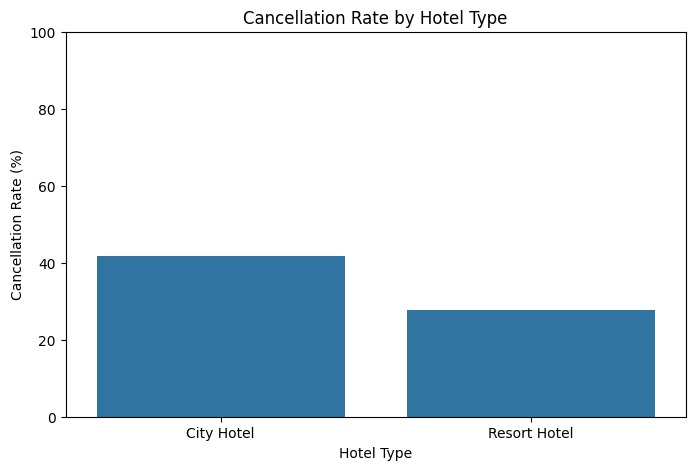

In [ ]:
# Visualize cancellation rates by hotel type

cancellation_rates = (df.groupby("hotel")["is_canceled"].mean() * 100)

plt.figure(figsize=(8, 5))

sns.barplot(x=cancellation_rates.index, y=cancellation_rates.values)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)

plt.show()

### 6.3 Booking Patterns and Seasonality

**Business Question:** Which months receive the most bookings, and how does seasonal demand differ between City Hotel and Resort Hotel?

In [ ]:
# Count bookings by arrival month
monthly_bookings = (
    df.groupby(["arrival_month_number", "arrival_date_month"])
    .size()
    .reset_index(name="total_bookings")
    .sort_values("arrival_month_number"))

print(monthly_bookings)

    arrival_month_number arrival_date_month  total_bookings
0                      1            January            5921
1                      2           February            8052
2                      3              March            9767
3                      4              April           11078
4                      5                May           11780
5                      6               June           10929
6                      7               July           12644
7                      8             August           13861
8                      9          September           10500
9                     10            October           11147
10                    11           November            6771
11                    12           December            6759


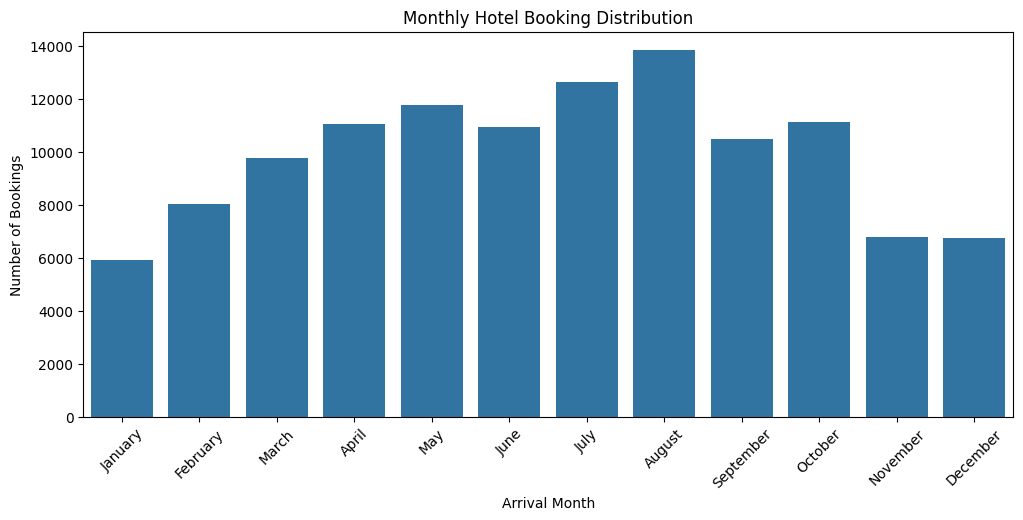

In [ ]:
# Visualize monthly booking distribution

plt.figure(figsize=(12, 5))

sns.barplot(data=monthly_bookings, x="arrival_date_month", y="total_bookings")

plt.title("Monthly Hotel Booking Distribution")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.show()

### 6.3.1 Adjusted Monthly Booking Distribution

**Question:** How does monthly booking demand compare after accounting for the dataset's unequal date coverage?

In [ ]:
# Count bookings for each year and month
yearly_monthly_bookings = (df.groupby(["arrival_date_year", "arrival_month_number", "arrival_date_month"])
    .size()
    .reset_index(name="total_bookings"))

# Calculate average bookings per observed month
average_monthly_bookings = (yearly_monthly_bookings
    .groupby(["arrival_month_number", "arrival_date_month"])
    ["total_bookings"]
    .mean()
    .reset_index(name="average_bookings")
    .sort_values("arrival_month_number"))

print(average_monthly_bookings)

    arrival_month_number arrival_date_month  average_bookings
0                      1            January       2960.500000
1                      2           February       4026.000000
2                      3              March       4883.500000
3                      4              April       5539.000000
4                      5                May       5890.000000
5                      6               June       5464.500000
6                      7               July       4214.666667
7                      8             August       4620.333333
8                      9          September       5250.000000
9                     10            October       5573.500000
10                    11           November       3385.500000
11                    12           December       3379.500000


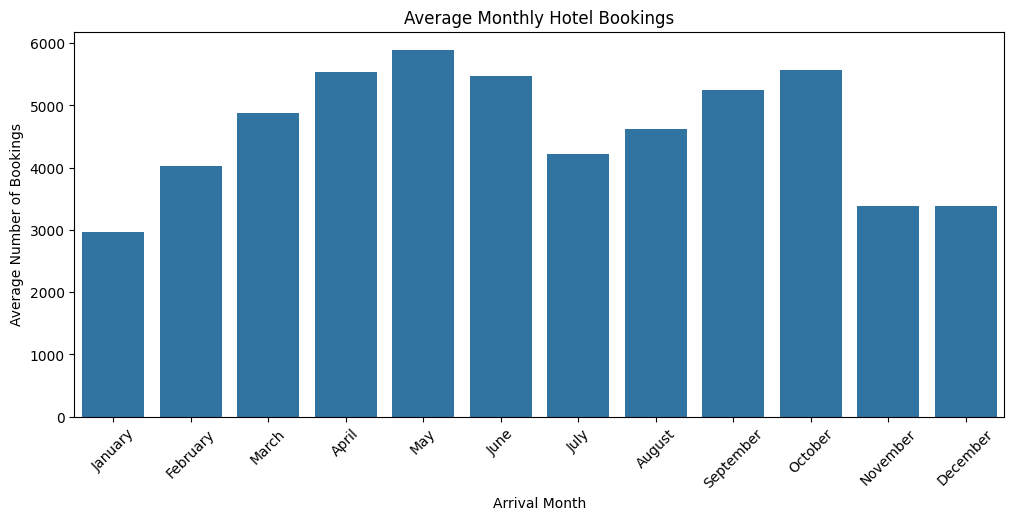

In [ ]:
# Visualize adjusted monthly bookings
plt.figure(figsize=(12, 5))

sns.barplot(data=average_monthly_bookings, x="arrival_date_month", y="average_bookings")

plt.title("Average Monthly Hotel Bookings")
plt.xlabel("Arrival Month")
plt.ylabel("Average Number of Bookings")
plt.xticks(rotation=45)

plt.show()

**Analysis:**

- May recorded the highest average booking count, with 5,890 bookings per observed month.
- January recorded the lowest average, with 2,960.5 bookings.
- April, May, June, September and October showed relatively high average booking volumes.
- After adjusting for unequal date coverage, August was no longer the month with the highest average booking count.

**Insight:**

The adjusted results suggest that booking demand varies throughout the year, with relatively high booking volumes during spring and autumn in the Northern Hemisphere.

However, the dataset covers July 2015 to August 2017, so these findings should be interpreted within the available observation period.

### 6.3.2 Seasonal Booking Patterns by Hotel Type

**Question:** How do monthly booking patterns differ between City Hotel and Resort Hotel?

In [ ]:
# Count monthly bookings by hotel and year

hotel_monthly_bookings = (df.groupby(["hotel", "arrival_date_year", "arrival_month_number", "arrival_date_month"])
    .size().reset_index(name="total_bookings"))

# Calculate average monthly bookings for each hotel

hotel_monthly_average = (hotel_monthly_bookings.groupby(["hotel", "arrival_month_number", "arrival_date_month"])["total_bookings"]
    .mean().reset_index(name="average_bookings").sort_values(["hotel", "arrival_month_number"]))

print(hotel_monthly_average)

           hotel  arrival_month_number arrival_date_month  average_bookings
0     City Hotel                     1            January       1865.000000
1     City Hotel                     2           February       2475.000000
2     City Hotel                     3              March       3217.000000
3     City Hotel                     4              April       3734.500000
4     City Hotel                     5                May       4110.500000
5     City Hotel                     6               June       3942.500000
6     City Hotel                     7               July       2690.333333
7     City Hotel                     8             August       2989.000000
8     City Hotel                     9          September       3696.000000
9     City Hotel                    10            October       3797.000000
10    City Hotel                    11           November       2168.000000
11    City Hotel                    12           December       2057.000000
12  Resort H

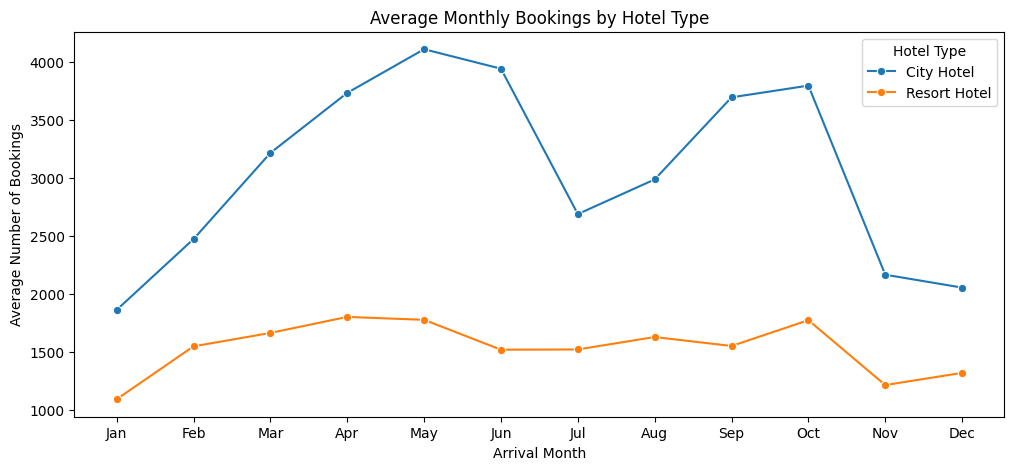

In [ ]:
# Compare seasonal booking patterns by hotel

plt.figure(figsize=(12, 5))

sns.lineplot(data=hotel_monthly_average,
    x="arrival_month_number", y="average_bookings", hue="hotel", marker="o")

plt.title("Average Monthly Bookings by Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Average Number of Bookings")

plt.xticks(
    range(1, 13),["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.legend(title="Hotel Type")
plt.show()

**Analysis:**

- City Hotel recorded higher average booking volumes than Resort Hotel in every month.
- City Hotel had its highest average in May (4,110.5 bookings) and its lowest in January (1,865).
- Resort Hotel had its highest average in April (1,804.5 bookings) and its lowest in January (1,095.5).
- City Hotel showed greater variation in monthly booking volumes, with particularly high averages in May, June, September and October.
- Both hotels recorded their lowest average booking volumes in January.

**Insight:**

The two hotel types exhibit different seasonal booking patterns. City Hotel experiences larger fluctuations in booking volume, whereas Resort Hotel has a relatively stable monthly distribution.

These findings can help inform staffing, capacity planning and seasonal marketing decisions.

**Limitation:** Monthly averages account for the number of observed years but not differences in month length or other sampling factors.

### 6.4 Booking Lead Time Analysis

**Question:** How does booking lead time relate to cancellation rates?

In [ ]:
# Calculate cancellation rates by lead time category

lead_time_cancellation = (df.groupby("lead_time_category", observed=True)["is_canceled"]
    .agg(["count", "mean"]))

lead_time_cancellation["cancellation_rate"] = (lead_time_cancellation["mean"] * 100)

print(lead_time_cancellation)

                    count      mean  cancellation_rate
lead_time_category                                    
0-7 days            19635  0.096002           9.600204
8-30 days           18945  0.278860          27.885986
31-90 days          29529  0.377290          37.729012
91-180 days         26420  0.447350          44.735049
181+ days           24680  0.570138          57.013776


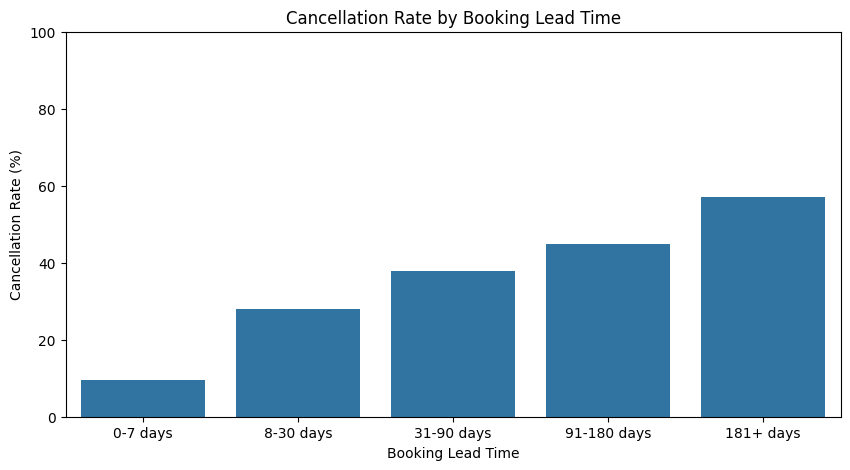

In [ ]:
# Visualize cancellation rates by lead time

plt.figure(figsize=(10, 5))

sns.barplot(x=lead_time_cancellation.index, y=lead_time_cancellation["cancellation_rate"])

plt.title("Cancellation Rate by Booking Lead Time")
plt.xlabel("Booking Lead Time")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)

plt.show()

**Analysis:**

- Bookings made 0–7 days before arrival had the lowest cancellation rate (9.60%).
- Bookings made 181+ days in advance had the highest cancellation rate (57.01%).
- Cancellation rates increased consistently across all five lead time categories.
- Bookings made more than 180 days in advance were approximately six times as likely to be canceled as bookings made within seven days of arrival.

**Insight:**

Booking lead time is strongly associated with cancellation behavior in this dataset. Hotels could use this information to improve cancellation forecasting, demand planning and reservation management.

However, other factors, such as deposit type, hotel type and customer segment, may also influence cancellation behavior.

### 6.5 Deposit Type and Booking Cancellations

**Question:** How do cancellation rates differ between deposit types?

In [ ]:
# Calculate cancellation rates by deposit type

deposit_cancellation = (df.groupby("deposit_type")["is_canceled"]
    .agg(["count", "mean"]))

deposit_cancellation["cancellation_rate"] = (deposit_cancellation["mean"] * 100)

print(deposit_cancellation)

               count      mean  cancellation_rate
deposit_type                                     
No Deposit    104460  0.284023          28.402259
Non Refund     14587  0.993624          99.362446
Refundable       162  0.222222          22.222222


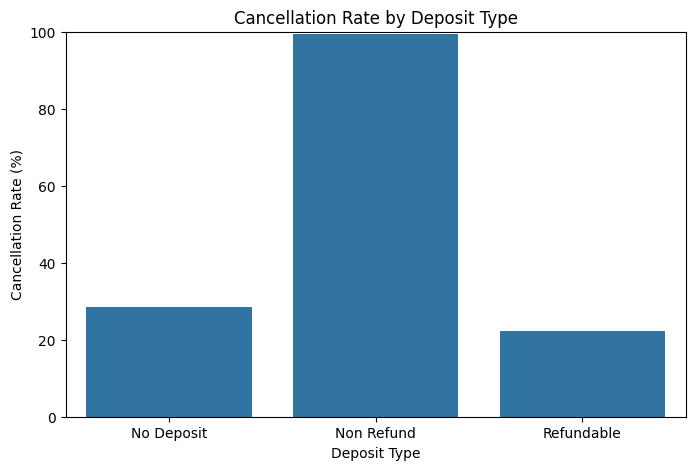

In [ ]:
# Visualize cancellation rates by deposit type

plt.figure(figsize=(8, 5))

sns.barplot(data=deposit_cancellation.reset_index(),
    x="deposit_type",
    y="cancellation_rate")

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)

plt.show()

**Analysis:**

- Non-refundable bookings had the highest cancellation rate (99.36%).
- Bookings without a deposit had a cancellation rate of 28.40%.
- Refundable bookings had the lowest cancellation rate (22.22%), although this category contained only 162 bookings.
- The unusually high cancellation rate for non-refundable bookings requires further investigation.

**Insight:**

Deposit type is strongly associated with booking cancellations in this dataset.

Hotels should investigate the unusually high cancellation rate among non-refundable bookings before making changes to their deposit policies.

The small number of refundable bookings also means that comparisons involving this category should be interpreted cautiously.

### 6.6 Customer Segment and Cancellation Analysis

In [ ]:
# Calculate cancellation rates by customer segment

segment_cancellation = (df.groupby("market_segment")["is_canceled"].agg(["count", "mean"]))

segment_cancellation["cancellation_rate"] = (segment_cancellation["mean"] * 100)

print(segment_cancellation)


                count      mean  cancellation_rate
market_segment                                    
Aviation          235  0.221277          22.127660
Complementary     728  0.122253          12.225275
Corporate        5282  0.187618          18.761833
Direct          12582  0.153712          15.371165
Groups          19790  0.611117          61.111673
Offline TA/TO   24182  0.343313          34.331321
Online TA       56408  0.367590          36.758970
Undefined           2  1.000000         100.000000


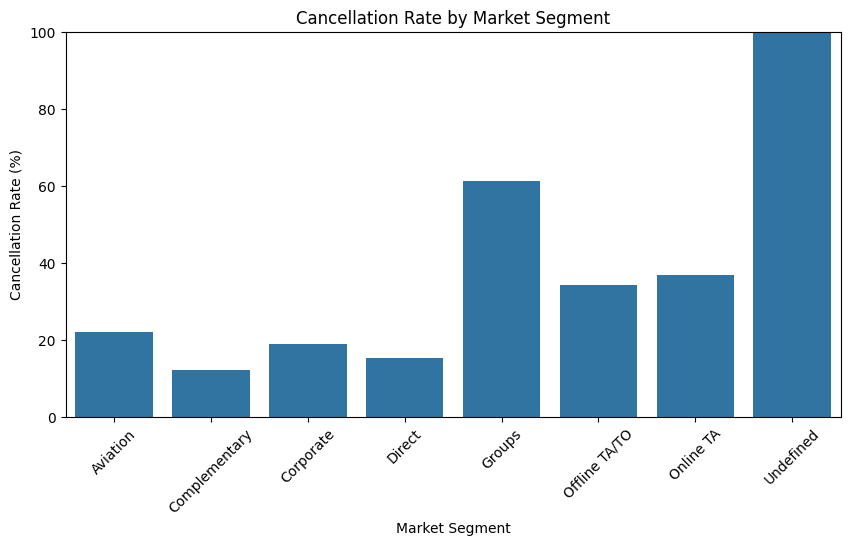

In [ ]:
# Visualize cancellation rates by customer segment

plt.figure(figsize=(10, 5))

sns.barplot(data=segment_cancellation.reset_index(),
    x="market_segment",
    y="cancellation_rate")

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)

plt.show()


**Analysis:**

- The Groups segment recorded the highest cancellation rate among major customer segments (61.11%).
- Online TA accounted for the largest booking volume (56,408 bookings), with a cancellation rate of 36.76%.
- Offline TA/TO bookings had a cancellation rate of 34.33%.
- Direct bookings had a comparatively low cancellation rate of 15.37%.
- The Complementary segment recorded a cancellation rate of 12.23%.
- The Undefined segment had a 100% cancellation rate, but it contained only two bookings and is therefore not representative.

**Insight:**

Cancellation behavior varies considerably across customer segments.

The high cancellation rate among group bookings suggests that hotels should investigate group reservation policies, booking lead times and deposit arrangements.

Online travel agencies generate substantial booking volumes but also contribute to cancellations. Hotels could use segment-level cancellation patterns to improve demand forecasting and reservation management.

These findings describe associations rather than proving that customer segments directly cause cancellations.

### 6.7 Deposit Type and Customer Segment

**Question**: Which customer segments account for non-refundable bookings, and how do their cancellation rates differ?

In [ ]:
# Filter non-refundable bookings

non_refund = df[df["deposit_type"] == "Non Refund"]

# Calculate booking counts and cancellation rates by segment

non_refund_segments = (non_refund.groupby("market_segment")["is_canceled"].agg(["count", "mean"]))

non_refund_segments["cancellation_rate"] = (non_refund_segments["mean"] * 100)

print(non_refund_segments)

                count      mean  cancellation_rate
market_segment                                    
Corporate         334  0.934132          93.413174
Direct             19  0.842105          84.210526
Groups           9172  0.993240          99.324030
Offline TA/TO    5006  0.999401          99.940072
Online TA          56  0.946429          94.642857


In [ ]:
# Compare booking counts across deposit types and segments

deposit_segment = pd.crosstab(df["market_segment"], df["deposit_type"])

print(deposit_segment)

deposit_type    No Deposit  Non Refund  Refundable
market_segment                                    
Aviation               235           0           0
Complementary          728           0           0
Corporate             4944         334           4
Direct               12557          19           6
Groups               10488        9172         130
Offline TA/TO        19172        5006           4
Online TA            56334          56          18
Undefined                2           0           0


**Analysis:**

- Groups accounted for 9,172 non-refundable bookings, with a cancellation rate of 99.32%.
- Offline TA/TO accounted for 5,006 non-refundable bookings, with a cancellation rate of 99.94%.
- Corporate bookings had a cancellation rate of 93.41%.
- Direct and Online TA had relatively few non-refundable bookings.
- Non-refundable bookings were concentrated primarily in Groups and Offline TA/TO.

**Insight:**

The unusually high cancellation rate among non-refundable bookings is observed across multiple customer segments.

Hotels should investigate group booking arrangements, travel agency contracts and reservation records to understand this pattern.

The findings suggest that deposit type and market segment should be examined together when developing cancellation forecasting models.

## 6.8 Customer Type and Cancellation Analysis

**Question:** How are bookings distributed across customer types, and how do their cancellation rates differ?

In [ ]:
# Calculate booking counts and cancellation rates by customer type

customer_cancellation = (df.groupby("customer_type")["is_canceled"].agg(["count", "mean"]))

customer_cancellation["cancellation_rate"] = (customer_cancellation["mean"] * 100)

print(customer_cancellation)

                 count      mean  cancellation_rate
customer_type                                      
Contract          4072  0.309921          30.992141
Group              574  0.101045          10.104530
Transient        89476  0.407864          40.786356
Transient-Party  25087  0.254514          25.451429


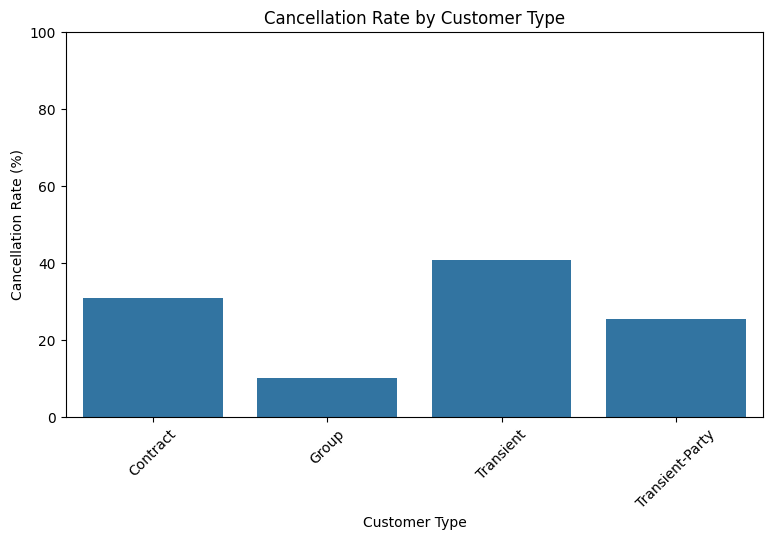

In [ ]:
# Visualize cancellation rates by customer type

plt.figure(figsize=(9, 5))

sns.barplot(data=customer_cancellation.reset_index(),
    x="customer_type",
    y="cancellation_rate")

plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)

plt.show()

**Analysis:**

- Transient customers accounted for the largest booking volume (89,476 bookings) and had the highest cancellation rate (40.79%).
- Contract customers recorded a cancellation rate of 30.99%.
- Transient-Party customers had a cancellation rate of 25.45%.
- Group customers had the lowest cancellation rate (10.10%), although they accounted for only 574 bookings.

**Insight:**

Customer type is associated with differences in booking cancellation behavior.

Transient customers represent the largest booking category and have the highest cancellation rate, making them an important segment for cancellation forecasting.

Hotels could investigate booking lead times, deposit arrangements and reservation channels among transient customers to better understand their cancellation patterns.

The Group customer type should not be confused with the Groups market segment, as these represent different classifications in the dataset.

## 6.9 Repeated Guests and Cancellation Analysis

**Question:** How do booking volumes and cancellation rates differ between repeated and non-repeated guests?

In [ ]:
# Calculate booking counts and cancellation rates by guest history

repeat_cancellation = (df.groupby("is_repeated_guest")["is_canceled"].agg(["count", "mean"]))

repeat_cancellation["cancellation_rate"] = (repeat_cancellation["mean"] * 100)

print(repeat_cancellation)

                    count      mean  cancellation_rate
is_repeated_guest                                     
0                  115455  0.378061          37.806072
1                    3754  0.146510          14.651039


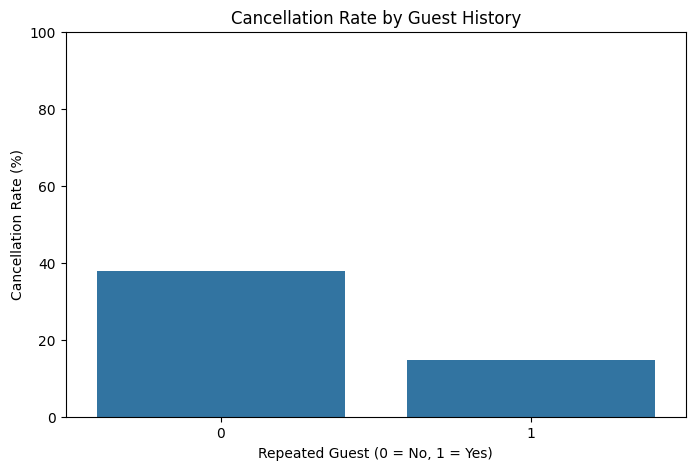

In [ ]:
# Visualize cancellation rates by guest history

plt.figure(figsize=(8, 5))

sns.barplot(data=repeat_cancellation.reset_index(),
    x="is_repeated_guest",
    y="cancellation_rate")

plt.title("Cancellation Rate by Guest History")
plt.xlabel("Repeated Guest (0 = No, 1 = Yes)")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)

plt.show()

**Analysis:**

- Non-repeated guests accounted for 115,455 bookings, with a cancellation rate of 37.81%.
- Repeated guests accounted for 3,754 bookings, with a cancellation rate of 14.65%.
- Non-repeated guests were approximately 2.6 times as likely to cancel their bookings as repeated guests.
- Repeated guests represented a relatively small proportion of total bookings.

**Insight:**

Previous guest history is associated with booking cancellation behavior.

Repeated guests had substantially lower cancellation rates, suggesting that guest retention may be relevant to reservation stability.

Hotels could investigate loyalty programs and personalized offers to encourage repeat bookings while improving cancellation forecasting.

These results show an association and do not establish that repeat visits directly reduce cancellations.

## 6.10 Room Type Changes and Cancellation Analysis

**Question:** How frequently do assigned room types differ from reserved room types, and how do cancellation rates differ between bookings with and without room type changes?

In [ ]:
# Calculate booking counts and cancellation rates by room type change

room_cancellation = (df.groupby("room_type_changed")["is_canceled"].agg(["count", "mean"]))

room_cancellation["cancellation_rate"] = (room_cancellation["mean"] * 100)

print(room_cancellation)

                    count      mean  cancellation_rate
room_type_changed                                     
0                  104414  0.415634          41.563392
1                   14795  0.054140           5.413991


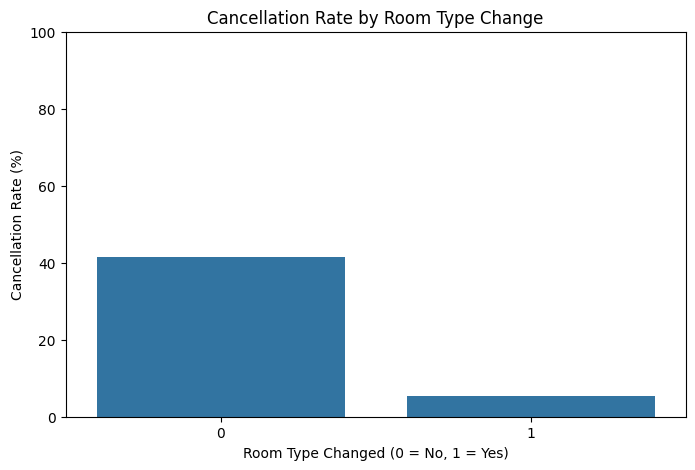

In [ ]:
# Visualize cancellation rates by room type change

plt.figure(figsize=(8, 5))

sns.barplot(data=room_cancellation.reset_index(),
    x="room_type_changed",
    y="cancellation_rate")

plt.title("Cancellation Rate by Room Type Change")
plt.xlabel("Room Type Changed (0 = No, 1 = Yes)")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)

plt.show()

**Analysis:**

- Bookings without a recorded room type change accounted for 104,414 reservations, with a cancellation rate of 41.56%.
- Bookings with a room type change accounted for 14,795 reservations, with a cancellation rate of 5.41%.
- A substantial difference in cancellation rates was observed between the two categories.

**Insight:**

Room type changes are associated with cancellation status in this dataset.

However, assigned room types may be updated after check-in, meaning that the relationship could reflect the hotel's room allocation process rather than the effect of room changes on cancellations.

This variable should be treated cautiously in cancellation forecasting because the final assigned room type may not be known when a reservation is initially made.

## 6.11 Special Requests and Cancellation Analysis

**Question:** How do booking volumes and cancellation rates differ according to the number of special requests made by guests?

In [ ]:
# Calculate cancellation rates by number of special requests

request_cancellation = (df.groupby("total_of_special_requests")["is_canceled"].agg(["count", "mean"]))

request_cancellation["cancellation_rate"] = (request_cancellation["mean"] * 100)

print(request_cancellation)

                           count      mean  cancellation_rate
total_of_special_requests                                    
0                          70200  0.477692          47.769231
1                          33183  0.220474          22.047434
2                          12952  0.221279          22.127857
3                           2494  0.178428          17.842823
4                            340  0.105882          10.588235
5                             40  0.050000           5.000000


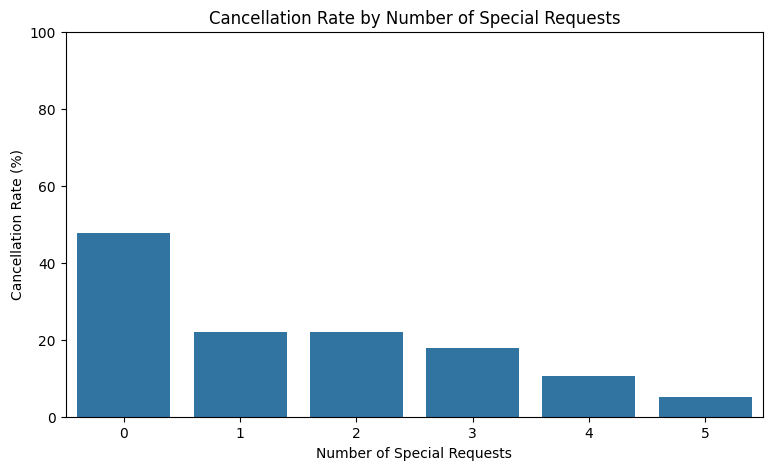

In [ ]:
# Visualize cancellation rates by number of special requests

plt.figure(figsize=(9, 5))

sns.barplot(data=request_cancellation.reset_index(),
    x="total_of_special_requests",
    y="cancellation_rate")

plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)

plt.show()

**Analysis:**

- Bookings with no special requests accounted for 70,200 reservations and had a cancellation rate of 47.77%.
- Bookings with one or two special requests had cancellation rates of approximately 22%.
- Bookings with three, four and five special requests had cancellation rates of 17.84%, 10.59% and 5%, respectively.
- Categories with four or five requests contained relatively few bookings, so their cancellation rates should be interpreted cautiously.

**Insight:**

Bookings with more special requests generally had lower cancellation rates, suggesting an association between special requests and booking commitment.

However, this relationship does not establish that making special requests reduces cancellations. Other factors, such as customer type, deposit policy and booking lead time, may also influence cancellation behavior.

## 6.12 Average Daily Rate (ADR) Analysis

**Question:** How does the Average Daily Rate (ADR) differ between City Hotel and Resort Hotel, and how does it vary across arrival months?

In [ ]:
# Calculate ADR statistics for completed stays

completed_bookings = df[(df["reservation_status"] == "Check-Out") & (df["adr"] > 0)]

hotel_adr = (completed_bookings.groupby("hotel")["adr"]
    .agg(["count", "mean", "median", "min", "max"]).round(2))

print(hotel_adr)

              count    mean  median   min    max
hotel                                           
City Hotel    45119  108.30   100.3  1.00  510.0
Resort Hotel  28269   92.94    74.0  0.26  508.0


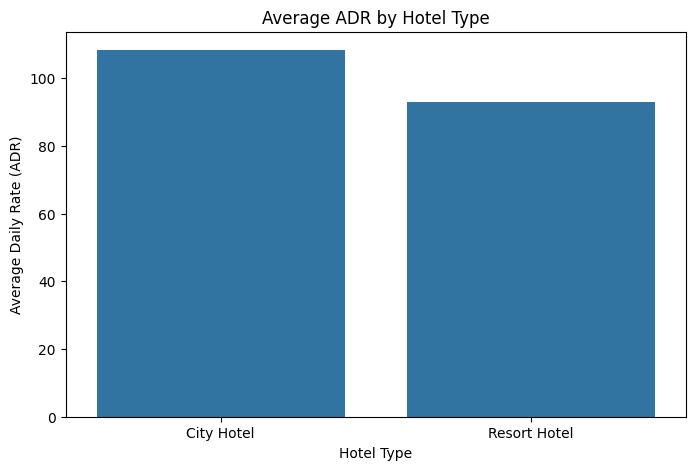

In [ ]:
# Compare average ADR between hotel types

plt.figure(figsize=(8, 5))

sns.barplot(data=hotel_adr.reset_index(),
    x="hotel",
    y="mean")

plt.title("Average ADR by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")

plt.show()

**Analysis:**

- City Hotel recorded an average ADR of 108.30, compared with 92.94 for Resort Hotel.
- City Hotel also had a higher median ADR (100.30) than Resort Hotel (74.00).
- The maximum recorded ADR was similar for both hotels, at 510 and 508, respectively.

**Insight:**

City Hotel generated a higher average daily room rate across completed bookings with positive ADR.

However, overall averages do not reveal how pricing changes throughout the year. Analyzing monthly ADR will help identify seasonal pricing patterns and differences between the two hotel types.

## 6.12.1 Monthly ADR Analysis

**Business Question:** How does the average daily rate vary across arrival months for City Hotel and Resort Hotel?

In [ ]:
# Calculate average ADR by hotel and arrival month

monthly_adr = (completed_bookings.groupby(["hotel", "arrival_month_number", "arrival_date_month"])["adr"]
    .mean()
    .reset_index(name="average_adr")
    .sort_values(["hotel", "arrival_month_number"]))

print(monthly_adr.round(2))

           hotel  arrival_month_number arrival_date_month  average_adr
0     City Hotel                     1            January        84.39
1     City Hotel                     2           February        88.37
2     City Hotel                     3              March        92.11
3     City Hotel                     4              April       113.52
4     City Hotel                     5                May       123.18
5     City Hotel                     6               June       119.66
6     City Hotel                     7               July       117.97
7     City Hotel                     8             August       120.95
8     City Hotel                     9          September       115.56
9     City Hotel                    10            October       104.62
10    City Hotel                    11           November        89.25
11    City Hotel                    12           December        92.32
12  Resort Hotel                     1            January        50.24
13  Re

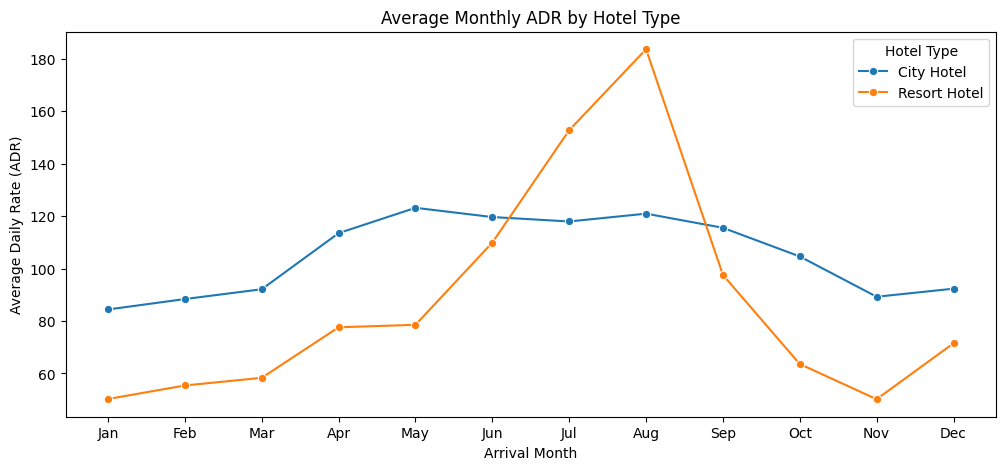

In [ ]:
# Compare monthly ADR between hotel types

plt.figure(figsize=(12, 5))

sns.lineplot(data=monthly_adr,
    x="arrival_month_number",
    y="average_adr",
    hue="hotel",
    marker="o")

plt.title("Average Monthly ADR by Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Average Daily Rate (ADR)")

plt.xticks(range(1, 13),["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.legend(title="Hotel Type")
plt.show()

**Analysis:**

- City Hotel maintains relatively stable ADR throughout the year, with its highest average of 123.18 in May.
- Resort Hotel experiences substantial seasonal fluctuations, reaching its highest ADR of 183.69 in August.
- Resort Hotel has a higher ADR than City Hotel during July and August.
- Resort Hotel's lowest ADR occurs in November (50.15).

**Insight:**

Resort Hotel exhibits stronger seasonal pricing patterns, particularly during July and August. City Hotel maintains comparatively consistent pricing throughout the year.

## 6.13 Revenue Analysis

**Question:** How does estimated completed-stay revenue differ between City Hotel and Resort Hotel?

In [ ]:
# Calculate estimated completed-stay revenue by hotel type

hotel_revenue = (df.groupby("hotel")["completed_stay_revenue"]
    .agg(["count", "sum", "mean"]).round(2))

print(hotel_revenue)

              count          sum    mean
hotel                                   
City Hotel    79163  14385342.00  181.72
Resort Hotel  40046  11601634.03  289.71


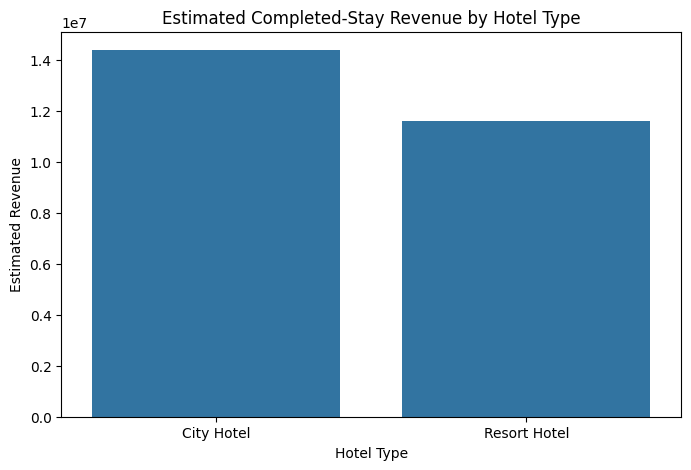

In [ ]:
# Visualize total estimated completed-stay revenue

plt.figure(figsize=(8, 5))

sns.barplot(data=hotel_revenue.reset_index(),
    x="hotel",
    y="sum")

plt.title("Estimated Completed-Stay Revenue by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Estimated Revenue")

plt.show()

**Analysis:**

- City Hotel generated approximately 14.39 million in estimated completed-stay revenue, compared with 11.60 million for Resort Hotel.
- City Hotel recorded a higher total number of bookings (79,163 versus 40,046).
- Resort Hotel generated higher average estimated revenue per booking (289.71) than City Hotel (181.72).

**Insight:**

City Hotel generates more total estimated revenue, supported by its larger booking volume. Resort Hotel generates higher average revenue per booking, suggesting differences in booking value and stay characteristics.

These figures represent estimated room revenue rather than verified actual revenue.

## 6.14 Length of Stay Analysis

**Question:** How does the length of stay differ between City Hotel and Resort Hotel?

In [ ]:
# Filter completed stays with at least one night

completed_stays = df[(df["reservation_status"] == "Check-Out") & (df["total_nights"] > 0)]

# Calculate length of stay statistics by hotel

hotel_stays = (completed_stays.groupby("hotel")["total_nights"]
    .agg(["count", "mean", "median", "min", "max"]).round(2))

print(hotel_stays)

              count  mean  median  min  max
hotel                                      
City Hotel    45833  2.93     3.0    1   48
Resort Hotel  28555  4.20     3.0    1   69


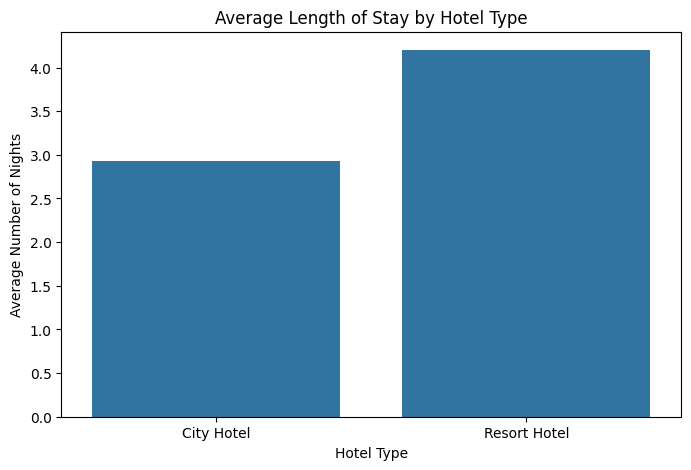

In [ ]:
# Compare average length of stay by hotel

plt.figure(figsize=(8, 5))

sns.barplot(data=hotel_stays.reset_index(),
    x="hotel",
    y="mean")

plt.title("Average Length of Stay by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Number of Nights")

plt.show()

**Analysis:**

- City Hotel has an average stay of 2.93 nights, compared with 4.20 nights at Resort Hotel.
- Both hotel types have a median stay of 3 nights.
- The longest recorded completed stay is 48 nights at City Hotel and 69 nights at Resort Hotel.

**Insight:**

Resort Hotel has a longer average length of stay, although the median is identical for both hotel types. Longer stays may contribute to Resort Hotel's higher estimated revenue per booking.

These results include only completed stays of at least one night.

## 6.15 Distribution Channel Analysis

**Question:** How are bookings distributed across different distribution channels, and how do their cancellation rates differ?

In [ ]:
# Calculate booking counts and cancellation rates by distribution channel

channel_cancellation = (df.groupby("distribution_channel")["is_canceled"].agg(["count", "mean"]))

channel_cancellation["cancellation_rate"] = (channel_cancellation["mean"] * 100)

print(channel_cancellation.round(2))

                      count  mean  cancellation_rate
distribution_channel                                
Corporate              6651  0.22              22.06
Direct                14610  0.17              17.49
GDS                     193  0.19              19.17
TA/TO                 97750  0.41              41.06
Undefined                 5  0.80              80.00


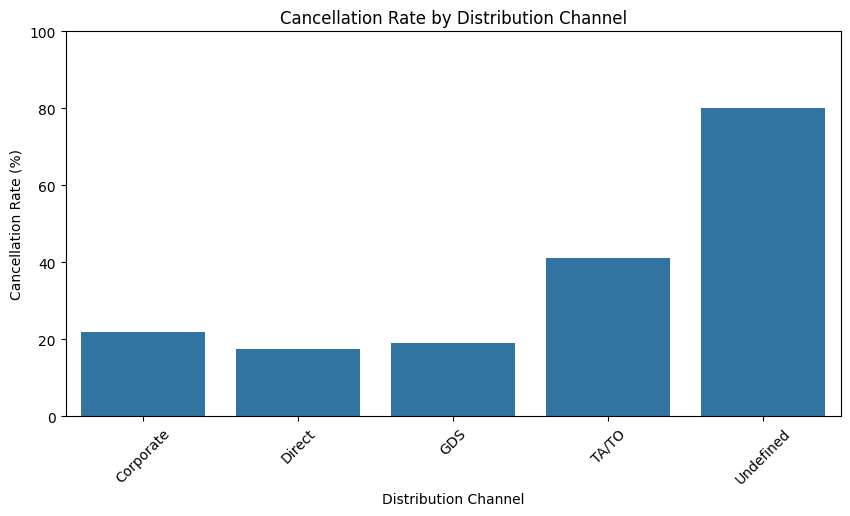

In [ ]:
# Visualize cancellation rates by distribution channel

plt.figure(figsize=(10, 5))

sns.barplot(data=channel_cancellation.reset_index(),
    x="distribution_channel",
    y="cancellation_rate")

plt.title("Cancellation Rate by Distribution Channel")
plt.xlabel("Distribution Channel")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)

plt.show()

**Analysis:**

- TA/TO is the largest distribution channel, accounting for 97,750 bookings, with a cancellation rate of 41.06%.
- Direct bookings have the lowest cancellation rate among the major distribution channels, at 17.49%.
- Corporate bookings have a cancellation rate of 22.06%, while GDS bookings have a rate of 19.17%.
- The Undefined category has an 80% cancellation rate but contains only five bookings, making it unsuitable for reliable comparisons.

**Insight:**

Bookings made through travel agents and tour operators represent the largest share of reservations and have a higher cancellation rate than direct bookings.

Hotels could investigate cancellation policies and booking patterns associated with third-party channels. Encouraging direct bookings may also be worth exploring, although these results do not establish that booking channels themselves cause cancellations.

## 6.16 Parking Requirements Analysis

**Question:** How do parking requirements differ between City Hotel and Resort Hotel?

In [ ]:
# Create a flag for bookings requiring parking

df["requires_parking"] = (df["required_car_parking_spaces"] > 0).astype(int)

# Calculate parking requirements by hotel type

hotel_parking = (df.groupby("hotel")["requires_parking"].agg(["count", "sum", "mean"]))

hotel_parking["parking_rate"] = (hotel_parking["mean"] * 100)

print(hotel_parking.round(2))

              count   sum  mean  parking_rate
hotel                                        
City Hotel    79163  1920  0.02          2.43
Resort Hotel  40046  5489  0.14         13.71


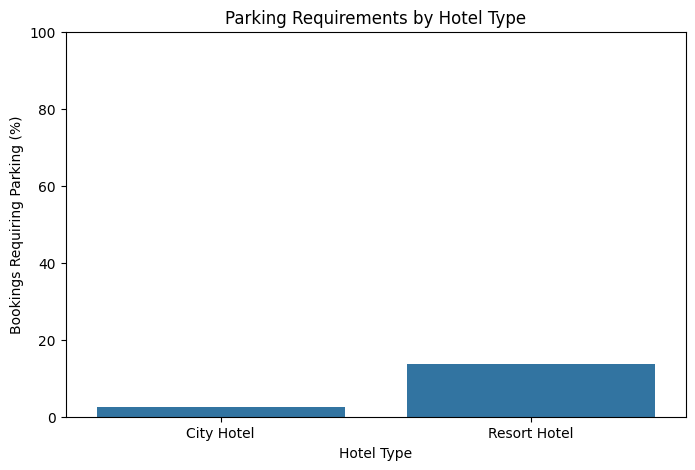

In [ ]:
# Visualize parking requirements by hotel type

plt.figure(figsize=(8, 5))

sns.barplot(data=hotel_parking.reset_index(),
    x="hotel",
    y="parking_rate")

plt.title("Parking Requirements by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Bookings Requiring Parking (%)")
plt.ylim(0, 100)

plt.show()

**Analysis:**

- City Hotel recorded 1,920 bookings requiring parking, representing 2.43% of its total bookings.
- Resort Hotel recorded 5,489 bookings requiring parking, representing 13.71% of its total bookings.
- Resort Hotel has a substantially higher proportion of bookings requesting parking despite having fewer total bookings.

**Insight:**

Parking demand differs considerably between the two hotel types. Resort Hotel may require greater parking capacity relative to its booking volume, while City Hotel has a much lower proportion of bookings requesting parking.

These figures represent parking requests rather than actual parking usage.

# 7. Key Findings and Business Recommendations

## 7.1 Key Findings

The exploratory data analysis identified several important patterns in hotel bookings, cancellations, customer behavior, pricing and estimated revenue.

**1. Booking Distribution and Cancellations**

- City Hotel accounts for 66.41% of bookings, while Resort Hotel accounts for 33.59%.
- The overall booking cancellation rate is 37.08%.
- City Hotel has a higher cancellation rate (41.79%) than Resort Hotel (27.77%).

**2. Booking Lead Time**

- Cancellation rates increase across longer booking lead-time categories.
- Bookings made 0–7 days before arrival have a cancellation rate of 9.60%.
- Bookings made more than 180 days in advance have a cancellation rate of 57.01%.

**3. Deposit Types and Distribution Channels**

- Non-refundable bookings have a cancellation rate of 99.36%, compared with 28.40% for bookings without a deposit.
- Travel agents and tour operators account for the largest distribution channel, with 97,750 bookings and a cancellation rate of 41.06%.
- Direct bookings have a comparatively lower cancellation rate of 17.49%.

**4. Customer Behavior**

- Repeated guests have a cancellation rate of 14.65%, compared with 37.81% for non-repeated guests.
- Bookings without special requests have a cancellation rate of 47.77%. Cancellation rates generally decrease as the number of special requests increases.

**5. Pricing and Revenue**

- City Hotel has a higher average ADR (108.30) than Resort Hotel (92.94) among completed bookings with positive ADR.
- Resort Hotel exhibits stronger seasonal pricing fluctuations, reaching an average ADR of 183.69 in August.
- City Hotel generates approximately 14.39 million in estimated completed-stay revenue, compared with 11.60 million for Resort Hotel.
- Resort Hotel has higher estimated completed-stay revenue per booking.

**6. Length of Stay and Parking**

- Resort Hotel has a longer average completed stay (4.20 nights) than City Hotel (2.93 nights).
- Parking is requested in 13.71% of Resort Hotel bookings, compared with 2.43% of City Hotel bookings.

## 7.2 Business Recommendations

**1. Improve Cancellation Management**

Hotels could introduce targeted booking reminders and reconfirmation procedures for reservations made far in advance. These bookings have higher observed cancellation rates.

**2. Investigate Non-Refundable Booking Cancellations**

The unusually high cancellation rate among non-refundable bookings requires further investigation. Hotels should examine cancellation policies, distribution channels and possible data-recording issues before making operational decisions.

**3. Strengthen Direct Booking Channels**

Direct bookings have a lower observed cancellation rate than bookings made through travel agents and tour operators.

Hotels could investigate direct-booking incentives and customer loyalty programs while considering differences in customer characteristics across channels.

**4. Develop Seasonal Pricing Strategies**

Resort Hotel experiences substantial seasonal fluctuations in ADR, particularly during July and August.

Hotels could use historical booking and pricing patterns to support seasonal revenue planning and evaluate opportunities during lower-demand periods.

**5. Improve Guest Retention**

Repeated guests demonstrate substantially lower cancellation rates than non-repeated guests.

Hotels could investigate loyalty programs, personalized offers and customer engagement strategies to encourage repeat bookings.

**6. Plan Parking Capacity**

Resort Hotel has a higher proportion of bookings requesting parking.

Hotel management could use these patterns alongside occupancy forecasts and actual parking usage to plan parking capacity.

## 7.3 Limitations of the Analysis

- The dataset covers bookings with arrival dates between July 2015 and August 2017. Findings may not represent current hotel booking behavior.
- The dataset contains two hotel types, so findings should not automatically be generalized to the entire hospitality industry.
- Estimated revenue is calculated using ADR multiplied by the number of booked nights for completed stays. It does not represent verified actual revenue.
- Bookings with zero guests and negative ADR were removed during data cleaning. One unusually high ADR was excluded from pricing calculations.
- Zero-night bookings were retained and flagged for separate analysis.
- Some categories contain very few bookings, making their cancellation rates less reliable for comparison.
- The observed relationships between booking characteristics and cancellation rates do not establish causation.

# 8. Final Dataset Validation

**Objective:** Verify the final dataset's structure, missing values, duplicates, data types and newly created columns before exporting it for further analysis.

## 8.1 Final Dataset Shape

In [ ]:
# Check final dataset shape

print("Final Dataset Shape:", df.shape)

Final Dataset Shape: (119209, 42)


## 8.2 Check Missing Values

In [ ]:
# Check missing values in the final dataset

missing_values = df.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
adr                  1
estimated_revenue    1
dtype: int64


## 8.3 Check Duplicate Records

In [ ]:
# Check duplicate records

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 31980


## 8.4 Verify New Analysis Columns

In [ ]:
# Check the data types of newly created columns

analysis_columns = ["is_zero_night", "total_nights", "total_guests", "arrival_month_number",
    "estimated_revenue",
    "completed_stay_revenue",
    "lead_time_category",
    "room_type_changed",
    "requires_parking"]

print(df[analysis_columns].dtypes)

is_zero_night                int64
total_nights                 int64
total_guests                 int64
arrival_month_number         int32
estimated_revenue          float64
completed_stay_revenue     float64
lead_time_category        category
room_type_changed            int64
requires_parking             int64
dtype: object


## 8.5 Validate Key Business Rules

In [ ]:
# Check important business rules

print("Bookings with zero guests:",
      (df["total_guests"] == 0).sum())

print("Negative ADR:",
      (df["adr"] < 0).sum())

print("Negative total nights:",
      (df["total_nights"] < 0).sum())

print("Zero-night bookings:",
      df["is_zero_night"].sum())

print("Bookings requiring parking:",
      df["requires_parking"].sum())

Bookings with zero guests: 0
Negative ADR: 0
Negative total nights: 0
Zero-night bookings: 645
Bookings requiring parking: 7409


## 8.6 Final Validation Summary

**Final Dataset:** 119,209 rows and 42 columns.

**Findings:**

- No bookings with zero guests remain.
- No negative ADR or negative stay lengths remain.
- One missing ADR and one missing estimated revenue are retained following the documented cleaning decision.
- 3,980 identical records were identified and retained because genuine duplicate bookings cannot be confirmed without unique booking identifiers.
- 645 zero-night bookings are retained and identified using the `is_zero_night` flag.
- 7,409 bookings require parking.
- All newly created analysis columns have the expected data types.

**Conclusion:**

The dataset has passed the defined business-rule checks and is ready for export, subject to the documented duplicate-record and missing-value limitations.

# 9. Export Cleaned Dataset

In [ ]:
# Export the cleaned dataset as CSV

df.to_csv("hotel_bookings_cleaned.csv", index=False)

# Download the CSV file
from google.colab import files

files.download("hotel_bookings_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>